## Análise de atenção: SSVEP + ritmo beta ao longo do tempo

*Kalil Nege — RA 2409020 · OPT098 - Tópicos Especiais em Sistemas de Computação (Prof. Dr. Rodrigo Hübner)*

Este notebook liga o desenvolvimento à revisão de literatura. O artigo *Predicting Attention Decline: An Integrated Beta-Band and SSVEP Approach* (Wei et al., IEEE TNSRE, 2026) mostra que a queda de atenção sustentada pode ser prevista combinando:

- a **amplitude/SNR do SSVEP**, que é modulada pela atenção (alvo atendido → resposta maior);
- a **potência na banda beta** (13–30 Hz), associada ao controle descendente (*top-down*);
- e a **razão teta/beta**, que tem correlação negativa com o controle atencional.

A base AVI **não possui rótulos de atenção** (nem tarefa comportamental). Por isso a análise abaixo é **exploratória**: usa os ensaios *single target* de 30 s (atenção sustentada em um único alvo) e observa como essas medidas evoluem ao longo do ensaio, como uma prova de conceito do monitoramento em tempo real com janela deslizante proposto em `EEG_Rhythms` e `Focus`.

Procedimento:
1. Janela deslizante de **2 s com passo de 1 s** (simulando um janela deslizante em tempo real) em cada ensaio;
2. Em cada janela: correlação CCA **na frequência atendida**, potência relativa beta e TBR. Como aqui o alvo é conhecido (não é classificação), a frequência estimulada e seus harmônicos são **removidos** do espectro antes de calcular beta e TBR, para que essas medidas reflitam só a atividade espontânea;
3. Comparar o início (0–10 s) com o final (20–30 s) do ensaio (teste de Wilcoxon pareado);
4. Verificar se as medidas espontâneas (beta, TBR) acompanham a força do SSVEP.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
from scipy import signal
from scipy.stats import wilcoxon, spearmanr

fs = 512
X = np.load('dados/single_x.npy')
y = np.load('dados/single_y.npy')
suj = np.load('dados/single_sub.npy')


def passa_faixa(sinal, corte_inf, corte_sup, fs=512, ordem=4):
    b, a = signal.butter(ordem, [corte_inf / (fs / 2), corte_sup / (fs / 2)], btype='bandpass')
    return signal.filtfilt(b, a, sinal)


def rejeita_faixa(sinal, corte, meia_banda=1, fs=512, ordem=4):
    b, a = signal.iirfilter(ordem, [(corte - meia_banda) / (fs / 2), (corte + meia_banda) / (fs / 2)],
                            btype='bandstop', ftype='butter')
    return signal.filtfilt(b, a, sinal)


X_f = np.array([passa_faixa(rejeita_faixa(x, 50), 1., 40.) for x in X])

In [2]:
def correlacao_cca(x, alvo, n_harm=3):
    t = np.arange(len(x)) / fs
    ref = np.column_stack([fun(2 * np.pi * h * alvo * t)
                           for h in range(1, n_harm + 1) for fun in (np.sin, np.cos)])
    coef, *_ = np.linalg.lstsq(ref, x, rcond=None)
    return np.corrcoef(ref @ coef, x)[0, 1]


def monitora(x, alvo, janela=2.0, passo=1.0):
    """Simula um buffer online: devolve, para cada janela, (cca, beta_rel, tbr)."""
    n, p = int(janela * fs), int(passo * fs)
    saida = []
    for i in range(0, len(x) - n + 1, p):
        seg = x[i:i + n]
        f, P = signal.welch(seg, fs=fs, nperseg=fs)
        # remove a frequência estimulada e os harmônicos (±0,5 Hz) para que
        # teta/beta meçam a atividade espontânea e não o próprio SSVEP
        livre = np.ones_like(f, dtype=bool)
        for h in (1, 2, 3, 4):
            livre &= np.abs(f - h * alvo) > 0.5
        total = P[livre & (f >= 1) & (f <= 40)].sum()
        teta = P[livre & (f >= 4) & (f < 8)].sum()
        beta = P[livre & (f >= 13) & (f < 30)].sum()
        saida.append((correlacao_cca(seg, alvo), beta / total, teta / beta))
    return np.array(saida)


S = np.array([monitora(x, alvo) for x, alvo in zip(X_f, y)])
print('(ensaios, janelas, medidas):', S.shape)
tempo = np.arange(S.shape[1]) + 1  # centro da janela de 2 s, em segundos

(ensaios, janelas, medidas): (92, 29, 3)


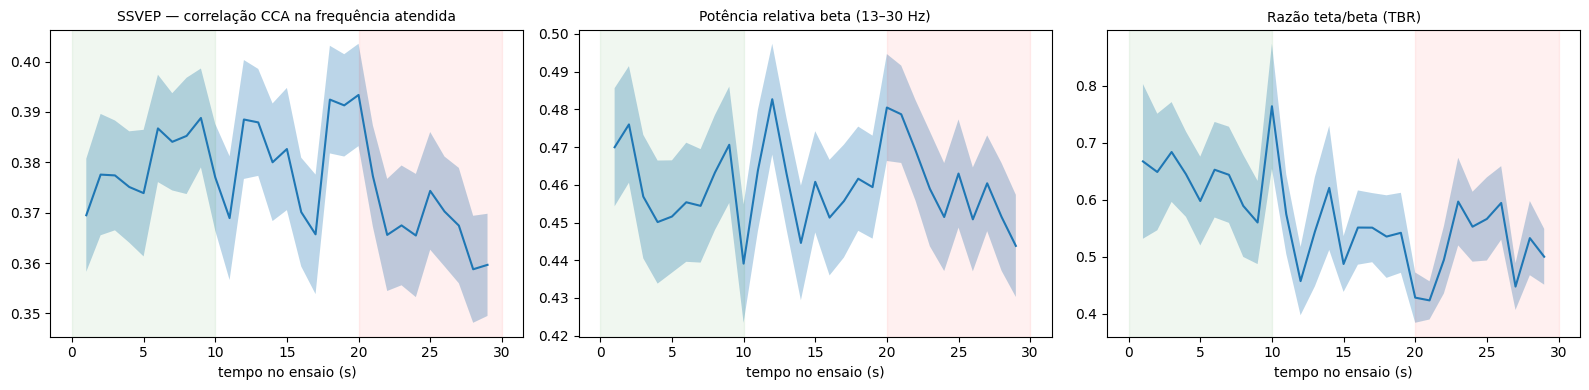

In [3]:
rcParams['figure.figsize'] = [16., 4.]
titulos = ('SSVEP — correlação CCA na frequência atendida', 'Potência relativa beta (13–30 Hz)', 'Razão teta/beta (TBR)')
fig, eixos = plt.subplots(1, 3)
for k, eixo in enumerate(eixos):
    media = S[:, :, k].mean(axis=0)
    erro = S[:, :, k].std(axis=0) / np.sqrt(S.shape[0])
    eixo.plot(tempo, media)
    eixo.fill_between(tempo, media - erro, media + erro, alpha=.3)
    eixo.axvspan(0, 10, color='green', alpha=.06); eixo.axvspan(20, 30, color='red', alpha=.06)
    eixo.set_title(titulos[k], fontsize=10); eixo.set_xlabel('tempo no ensaio (s)')
plt.tight_layout(); plt.show()

In [4]:
# início (0–10 s) vs final (20–30 s) de cada ensaio
ini = S[:, :9, :].mean(axis=1)
fim = S[:, -9:, :].mean(axis=1)
for k, nome in enumerate(('CCA (SSVEP)', 'beta relativa', 'TBR')):
    p = wilcoxon(ini[:, k], fim[:, k]).pvalue
    print(f'{nome:<14} início={ini[:, k].mean():.3f}  final={fim[:, k].mean():.3f}  '
          f'variação={100 * (fim[:, k].mean() / ini[:, k].mean() - 1):+.1f}%  p={p:.3f}')

CCA (SSVEP)    início=0.380  final=0.367  variação=-3.3%  p=0.065
beta relativa  início=0.461  final=0.459  variação=-0.5%  p=0.997
TBR            início=0.632  final=0.523  variação=-17.2%  p=0.049


In [5]:
# variação por participante (a média geral pode esconder diferenças individuais)
for s in np.unique(suj):
    m = suj == s
    print(f'Participante {s}: CCA {100 * (fim[m, 0].mean() / ini[m, 0].mean() - 1):+6.1f}% | '
          f'beta {100 * (fim[m, 1].mean() / ini[m, 1].mean() - 1):+6.1f}% | '
          f'TBR {100 * (fim[m, 2].mean() / ini[m, 2].mean() - 1):+6.1f}%')

Participante 1: CCA   -3.3% | beta   -7.3% | TBR  +12.2%
Participante 2: CCA   -4.2% | beta   -0.2% | TBR  -14.6%
Participante 3: CCA   -1.8% | beta   -1.8% | TBR  -11.7%
Participante 4: CCA   -3.6% | beta  +11.3% | TBR  -31.4%


### As medidas espontâneas acompanham o SSVEP?

Se beta e TBR refletem o mesmo estado atencional que modula o SSVEP, as janelas com SSVEP mais forte deveriam ter beta mais alta e TBR mais baixa. Para tirar o efeito de diferenças fixas entre ensaios e participantes, cada medida é normalizada (escore z) **dentro do ensaio** antes da correlação de Spearman.

CCA x beta: rho = +0.111  (p = 0.000)
CCA x TBR : rho = -0.110  (p = 0.000)


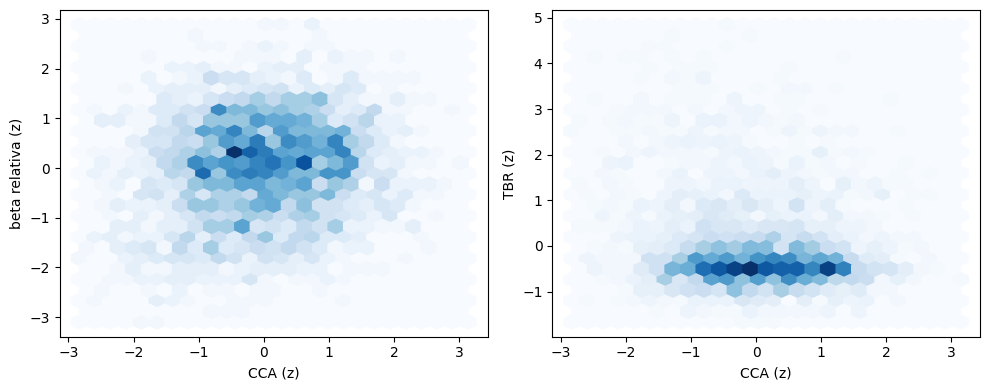

In [6]:
z = lambda a: (a - a.mean(axis=1, keepdims=True)) / a.std(axis=1, keepdims=True)
cca_z, beta_z, tbr_z = z(S[:, :, 0]).ravel(), z(S[:, :, 1]).ravel(), z(S[:, :, 2]).ravel()

for nome, v in (('beta', beta_z), ('TBR', tbr_z)):
    r, p = spearmanr(cca_z, v)
    print(f'CCA x {nome:<4}: rho = {r:+.3f}  (p = {p:.3f})')

rcParams['figure.figsize'] = [10., 4.]
fig, eixos = plt.subplots(1, 2)
for eixo, v, nome in zip(eixos, (beta_z, tbr_z), ('beta relativa (z)', 'TBR (z)')):
    eixo.hexbin(cca_z, v, gridsize=25, cmap='Blues'); eixo.set_xlabel('CCA (z)'); eixo.set_ylabel(nome)
plt.tight_layout(); plt.show()

### Discussão

- Ao longo dos 30 s, a resposta SSVEP (CCA) mostra uma **tendência de queda** do início para o final do ensaio (p ≈ 0,07), e a **razão teta/beta também diminui** (p ≈ 0,05). A potência beta relativa praticamente não muda. Os efeitos são pequenos e variam entre os participantes (o participante 1 vai na direção oposta na TBR), então não dá para afirmar que houve queda de atenção.
- Dentro de cada ensaio, depois de remover o pico do estímulo, as janelas com SSVEP mais forte têm **beta um pouco maior e TBR um pouco menor** (ρ ≈ +0,11 e −0,11, p < 0,001). É a direção prevista pela literatura (mais atenção → SSVEP maior, beta maior, TBR menor) e reproduz em pequena escala a ideia de Wei et al. de que as duas medidas carregam informação relacionada. A correlação, porém, é fraca (explica cerca de 1% da variância). No artigo, a fusão funciona melhor porque existe um **rótulo comportamental** (erros na tarefa *go/no-go*) e há vários canais frontais e parietais, enquanto aqui há um único canal occipital.
- **Limitações**: um único eletrodo (Oz), 4 participantes, ensaios curtos (30 s, pouco para induzir fadiga atencional) e ausência de rótulos de atenção. Como os estímulos (6–10 Hz) caem nas bandas teta e alfa, a alfa não foi usada como indicador, e a teta só foi usada depois de remover a frequência estimulada.

### Próximos passos (perspectivas)

1. Aplicar o mesmo roteiro aa base **BETA** (64 canais, 40 alvos de 8 a 15,8 Hz), usando os canais occipitais para SSVEP e os frontais/centrais para beta/TBR, com o SNR de banda larga também descrito no artigo;
2. Usar uma base de dados com rótulo de atenção (por exemplo, o de Mora-Cortes et al., 2017, com SSVEP sob atenção dividida) para treinar um classificador **atento vs. desatento** com a fusão SSVEP + beta;
3. Coletar dados próprios com o OpenBCI do laboratório em sessões longas, com uma tarefa comportamental para servir de rótulo.